# 1. Neural Networks from Scratch

Practice for module 1: linear layers and the bias trick, batched matrix multiplication,
activation functions, a 2-layer network trained on a non-linear problem, softmax,
and batch vs layer normalization.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 1.1 Linear layer and the bias trick

`Y = XW + b` (rows are examples). Appending a column of ones to `X` and the bias as an
extra row of `W` gives the same result with one matrix multiplication.

In [2]:
X = rng.normal(size=(4, 3))          # batch of 4 examples, 3 features
W = rng.normal(size=(3, 2))
b = np.array([0.5, -1.0])

Y = X @ W + b

X_aug = np.hstack([X, np.ones((4, 1))])
W_aug = np.vstack([W, b])
Y_aug = X_aug @ W_aug

print("XW + b:\n", Y)
print("bias trick equal:", np.allclose(Y, Y_aug))

XW + b:
 [[ 0.024 -1.133]
 [ 0.727 -0.745]
 [-3.329 -1.756]
 [ 4.196 -0.28 ]]
bias trick equal: True


## 1.2 Batch = same weights, many inputs

Processing examples one by one and as a batch gives identical outputs; the batch is just one matmul.

In [3]:
one_by_one = np.stack([x @ W + b for x in X])
print("loop == batch:", np.allclose(one_by_one, Y))

# Without an activation, two linear layers collapse into one
W2 = rng.normal(size=(2, 2))
print("two linear layers == one:", np.allclose((X @ W) @ W2, X @ (W @ W2)))

loop == batch: True
two linear layers == one: True


## 1.3 Activation functions and their derivatives

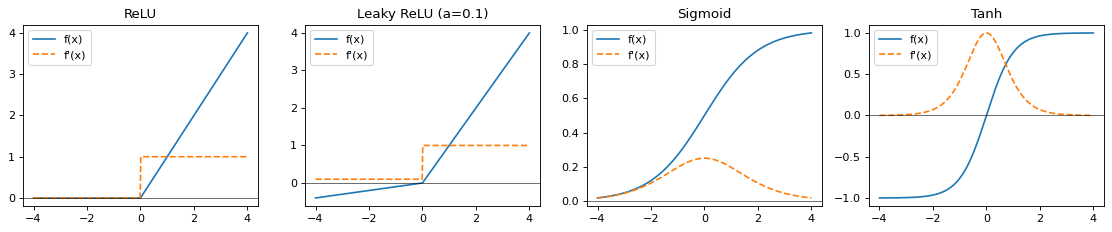

In [4]:
def relu(x): return np.maximum(0, x)
def leaky_relu(x, a=0.1): return np.where(x > 0, x, a * x)
def sigmoid(x): return 1 / (1 + np.exp(-x))
def tanh(x): return np.tanh(x)

z = np.linspace(-4, 4, 400)
acts = {
    "ReLU": (relu(z), (z > 0).astype(float)),
    "Leaky ReLU (a=0.1)": (leaky_relu(z), np.where(z > 0, 1, 0.1)),
    "Sigmoid": (sigmoid(z), sigmoid(z) * (1 - sigmoid(z))),
    "Tanh": (tanh(z), 1 - tanh(z) ** 2),
}
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (name, (f, df)) in zip(axes, acts.items()):
    ax.plot(z, f, label="f(x)")
    ax.plot(z, df, "--", label="f'(x)")
    ax.set_title(name); ax.axhline(0, color="k", lw=0.5); ax.legend()
plt.tight_layout(); plt.show()

## 1.4 A 2-layer network learns a non-linear decision boundary

Two concentric rings cannot be separated by a line. One hidden layer with ReLU + softmax output
(2 classes) learns a closed boundary. Backprop is written by hand.

final loss 0.003, train accuracy 1.000


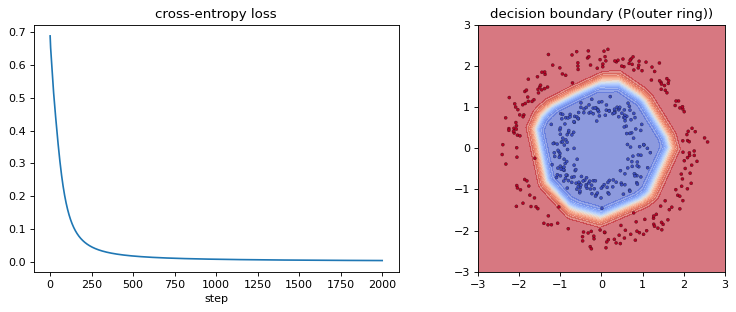

In [5]:
def make_rings(n=400):
    r = np.r_[rng.normal(1.0, 0.15, n // 2), rng.normal(2.2, 0.15, n // 2)]
    t = rng.uniform(0, 2 * np.pi, n)
    X = np.c_[r * np.cos(t), r * np.sin(t)]
    y = np.r_[np.zeros(n // 2, int), np.ones(n // 2, int)]
    return X, y

def softmax(z):
    z = z - z.max(axis=1, keepdims=True)    # numerical stability, result unchanged
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

Xr, yr = make_rings()
H, C = 16, 2
W1 = rng.normal(0, 0.5, (2, H)); b1 = np.zeros(H)
W2 = rng.normal(0, 0.5, (H, C)); b2 = np.zeros(C)
lr, losses = 0.2, []

for step in range(2000):
    z1 = Xr @ W1 + b1                 # matmul -> bias
    a1 = relu(z1)                     # -> activation
    p = softmax(a1 @ W2 + b2)
    Y1h = np.eye(C)[yr]
    losses.append(-np.mean(np.log(p[np.arange(len(yr)), yr] + 1e-12)))

    dz2 = (p - Y1h) / len(yr)         # softmax + cross-entropy gradient
    dW2, db2 = a1.T @ dz2, dz2.sum(0)
    dz1 = (dz2 @ W2.T) * (z1 > 0)
    dW1, db1 = Xr.T @ dz1, dz1.sum(0)
    W1 -= lr * dW1; b1 -= lr * db1; W2 -= lr * dW2; b2 -= lr * db2

acc = (p.argmax(1) == yr).mean()
print(f"final loss {losses[-1]:.3f}, train accuracy {acc:.3f}")

gx, gy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
G = np.c_[gx.ravel(), gy.ravel()]
prob = softmax(relu(G @ W1 + b1) @ W2 + b2)[:, 1].reshape(gx.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(losses); axes[0].set_title("cross-entropy loss"); axes[0].set_xlabel("step")
axes[1].contourf(gx, gy, prob, levels=20, cmap="coolwarm", alpha=0.6)
axes[1].scatter(*Xr.T, c=yr, cmap="coolwarm", s=8, edgecolor="k", lw=0.2)
axes[1].set_title("decision boundary (P(outer ring))"); axes[1].set_aspect("equal")
plt.tight_layout(); plt.show()

## 1.5 Softmax vs independent sigmoids

Softmax gives a distribution over classes (sums to 1); sigmoids per output do not.

In [6]:
logits = np.array([[2.0, 1.0, 0.1], [0.5, 0.5, 3.0]])
print("softmax:", softmax(logits), "row sums:", softmax(logits).sum(1))
print("sigmoid:", sigmoid(logits), "row sums:", sigmoid(logits).sum(1))
print("softmax is shift-invariant:", np.allclose(softmax(logits), softmax(logits + 100)))

softmax: [[0.659 0.242 0.099]
 [0.071 0.071 0.859]] row sums: [1. 1.]
sigmoid: [[0.881 0.731 0.525]
 [0.622 0.622 0.953]] row sums: [2.137 2.197]
softmax is shift-invariant: True


## 1.6 Batch Normalization vs Layer Normalization

BatchNorm: statistics per feature over the batch (axis 0). LayerNorm: statistics per example over
features (axis 1). A brightness-like shift of the whole batch disappears after BatchNorm.

In [7]:
def batch_norm(x, gamma, beta, eps=1e-5):
    mu, var = x.mean(0), x.var(0)
    return gamma * (x - mu) / np.sqrt(var + eps) + beta

def layer_norm(x, gamma, beta, eps=1e-5):
    mu, var = x.mean(1, keepdims=True), x.var(1, keepdims=True)
    return gamma * (x - mu) / np.sqrt(var + eps) + beta

A = rng.normal(5, 3, size=(8, 4))    # pre-activations: batch 8, 4 features
g, bt = np.ones(4), np.zeros(4)

bn, ln = batch_norm(A, g, bt), layer_norm(A, g, bt)
print("BN mean/std per feature :", bn.mean(0), bn.std(0))
print("LN mean/std per example :", ln.mean(1), ln.std(1))

shifted = A + 10                      # e.g. every image got brighter
print("BN removes the shift:", np.allclose(batch_norm(shifted, g, bt), bn))

# gamma/beta rescale and shift the normalized output
print("gamma=2, beta=1 -> mean/std:", batch_norm(A, 2 * g, bt + 1).mean(0), batch_norm(A, 2 * g, bt + 1).std(0))

# LayerNorm does not care about batch size: one example works
print("LN on a single example:", layer_norm(A[:1], g, bt))

BN mean/std per feature : [-0.  0.  0.  0.] [1. 1. 1. 1.]
LN mean/std per example : [ 0. -0. -0. -0.  0.  0.  0.  0.] [1. 1. 1. 1. 1. 1. 1. 1.]
BN removes the shift: True
gamma=2, beta=1 -> mean/std: [1. 1. 1. 1.] [2. 2. 2. 2.]
LN on a single example: [[-0.251 -0.396  1.66  -1.012]]
